# FK / IK / DH sandbox — Fusybots six-DOF spherical-wrist arm (fusybots_six_dof_spherical_wrist)

This notebook is the **Python prototyping sandbox** for `robot_fundamentals_ws`'s
`kinematics` package - specifically the `analytical` strategy
(`AnalyticalSixAxisForwardKinematics` / `AnalyticalSixAxisInverseKinematics`).

**Workflow this notebook follows (and the one this workspace follows in general):**
work out the math here first - symbolically, numerically, with plots you can actually
look at - *before* writing or changing any C++. Every formula below is a direct,
verified port of the real C++ implementation (see `verify_notebook_math.py`-style
checks embedded as assertions throughout), not a simplified toy version - if you
change something here and it still matches, you can port the same change to C++ with
confidence; if it doesn't match, you've found the bug before it ever reached C++.

Covers four things **separately**, on purpose (mirroring how this workspace's
packages are split): forward kinematics, inverse kinematics (incl. all 8 solutions),
verification (FK→IK→FK), and a short bonus section on trajectory planning.

Robot: 6R arm, joints 1-3 with a genuine shoulder offset, joints 4-6 a true
**spherical wrist** (all three axes intersect at one point - required for the
closed-form IK below to exist at all).

In [ ]:
!pip install matplotlib
!pip install numpy
!pip install scipy
!pip install sympy


In [40]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (registers 3d projection)

np.set_printoptions(precision=4, suppress=True)
sp.init_printing()


## 1. Robot geometry (link lengths)

Exactly matching `robot_config/config/robots/fusybots_six_dof_spherical_wrist.yaml`'s
`kinematics.link_lengths` block - this is the *only* place these numbers are
defined; everything below is a function of these seven values.

Note `l7 = 0.0`: this is the **spherical wrist** requirement (see Section 3) - axes
4, 5, 6 all pass through one point. `d2` here is *not* a real single link length -
it's `l2 - l4`, the leftover residual between two real link lengths that never got
their own DH table row (see the markdown note in Section 2).

In [41]:
l1 = 0.2    # base rise (F0->F1)
d2 = 0.01   # residual = l2 - l4 (NOT a real single physical segment - see note below)
l3 = 0.3    # upper-arm segment (F2->F3)
l5 = 0.32   # forearm segment (F3->F4)
l6 = 0.25   # F4->F5 segment - real, lies along joint 4's own axis
l7 = 0.0    # wrist offset - MUST be 0 for a true spherical wrist
le = 0.10   # fixed tool/flange extension beyond joint 6

print(f"l1={l1} d2={d2} l3={l3} l5={l5} l6={l6} l7={l7} le={le}")


l1=0.2 d2=0.01 l3=0.3 l5=0.32 l6=0.25 l7=0.0 le=0.1


## 2. Forward kinematics: the DH chain

Convention used here is **Craig's modified DH**: each row's transform is

```
T_i = Rot_x(alpha_i) . Trans_x(a_i) . Rot_z(theta_i) . Trans_z(d_i)
```

which multiplies out to the closed form used directly below (and in the C++):

```
T_i = [ c0    -s0      0        a   ]
      [ s0*ca  c0*ca  -sa      -d*sa]
      [ s0*sa  c0*sa   ca       d*ca]
      [ 0      0       0        1   ]
```

where `c0=cos(theta_i)`, `s0=sin(theta_i)`, `ca=cos(alpha_i)`, `sa=sin(alpha_i)`.

The chain has **7 rows**, not 6: rows 0-5 are the six real joints, row 6 is a
*fixed* tool-alignment transform (not a joint - theta is permanently -180 deg).

| row | alpha | a | d | theta | meaning |
|---|---|---|---|---|---|
| 0 | 0 | 0 | l1 | th1 + 90 deg | base rise, pure yaw axis, +90 deg is frame-alignment bookkeeping, not physics |
| 1 | 90 deg | 0 | 0 | th2 - 90 deg | **no length at all** - pure reorientation, yaw axis -> pitch axis |
| 2 | 0 | -l3 | d2 | th3 | real upper-arm link; d2 is the smeared residual, not a real segment |
| 3 | 0 | -l5 | l6 | th4 + 90 deg | real forearm link (a) AND real link along joint 4's axis (d) |
| 4 | -90 deg | 0 | l7=0 | th5 | first wrist twist - l7=0 is what makes the wrist spherical |
| 5 | 90 deg | 0 | 0 | th6 + 90 deg | second wrist twist, undoes row 4's twist direction |
| 6 (fixed) | 0 | 0 | le | -180 deg (constant) | tool offset, not a joint |

Every `+-90 deg` constant above is **not physics** - it's DH forcing each frame's
x-axis onto the common perpendicular between consecutive axes, which doesn't
generally match however the URDF happened to be authored at that joint.

In [42]:
def dh_transform_num(theta, d, a, alpha):
    """One DH row, Craig's modified convention - exactly the matrix used in
    AnalyticalSixAxisForwardKinematics::computeFk (kinematics/src/strategy/
    analytical_six_axis_forward_kinematics.cpp)."""
    ct, st = np.cos(theta), np.sin(theta)
    ca, sa = np.cos(alpha), np.sin(alpha)
    return np.array([
        [ct,      -st,      0,    a     ],
        [st * ca,  ct * ca, -sa, -d * sa],
        [st * sa,  ct * sa,  ca,  d * ca],
        [0,        0,        0,   1     ],
    ])


def compute_fk(n, theta):
    """Mirrors computeFk(n, theta) exactly: evaluate rows 0..min(len,7)-1,
    appending the fixed tool row (theta=-pi) when n > 6 and len(theta) == 6."""
    theta = list(theta)
    alpha = [0, np.pi / 2, 0, 0, -np.pi / 2, np.pi / 2, 0]
    a     = [0, 0, -l3, -l5, 0, 0, 0]
    d     = [l1, 0, d2, l6, l7, 0, le]

    adjusted = list(theta)
    adjusted[0] += np.pi / 2
    adjusted[1] -= np.pi / 2
    if len(theta) > 3:
        adjusted[3] += np.pi / 2
        adjusted[5] += np.pi / 2

    if n > 6:
        adjusted = adjusted + [-np.pi]

    num_rows = min(len(adjusted), 7)
    T = np.eye(4)
    for i in range(num_rows):
        T = T @ dh_transform_num(adjusted[i], d[i], a[i], alpha[i])
    return T


def compute_joint_frames(joint_positions):
    """T_(0,i) for i=0..6 (base + 6 joint frames), for plotting/Jacobians -
    mirrors computeJointFrames exactly (excludes the fixed tool row)."""
    alpha = [0, np.pi / 2, 0, 0, -np.pi / 2, np.pi / 2]
    a     = [0, 0, -l3, -l5, 0, 0]
    d     = [l1, 0, d2, l6, l7, 0]

    adjusted = list(joint_positions)
    adjusted[0] += np.pi / 2
    adjusted[1] -= np.pi / 2
    adjusted[3] += np.pi / 2
    adjusted[5] += np.pi / 2

    frames = [np.eye(4)]
    for i in range(6):
        frames.append(frames[-1] @ dh_transform_num(adjusted[i], d[i], a[i], alpha[i]))
    return frames


# quick sanity check: home pose from fusybots_six_dof_spherical_wrist.yaml
home = [0.0, 0.0, 1.57, 0.0, -1.57, 0.0]
print("FK at home pose:\n", compute_fk(7, home))


FK at home pose:
 [[ 0.      1.      0.0008  0.2601]
 [ 1.      0.     -0.0008 -0.3201]
 [-0.0008  0.0008 -1.      0.4003]
 [ 0.      0.      0.      1.    ]]


### 2.1 Symbolic FK (sympy)

Same chain, but with `sympy` symbols instead of numbers - lets you see the actual
closed-form expression for the end-effector pose as a function of the six joint
angles, and confirms the numeric version above isn't hiding a mistake (they're
built completely independently - one symbolic substitution, one a plain float
loop - so agreement between them is real evidence, not circular).

In [43]:
th1, th2, th3, th4, th5, th6 = sp.symbols('theta1 theta2 theta3 theta4 theta5 theta6', real=True)


def dh_transform_sym(theta, d, a, alpha):
    ct, st = sp.cos(theta), sp.sin(theta)
    ca, sa = sp.cos(alpha), sp.sin(alpha)
    return sp.Matrix([
        [ct,      -st,      0,    a     ],
        [st * ca,  ct * ca, -sa, -d * sa],
        [st * sa,  ct * sa,  ca,  d * ca],
        [0,        0,        0,   1     ],
    ])


alphas_sym = [0, sp.pi / 2, 0, 0, -sp.pi / 2, sp.pi / 2, 0]
a_sym      = [0, 0, -l3, -l5, 0, 0, 0]
d_sym      = [l1, 0, d2, l6, l7, 0, le]
theta_adj_sym = [th1 + sp.pi / 2, th2 - sp.pi / 2, th3,
                 th4 + sp.pi / 2, th5, th6 + sp.pi / 2, sp.Integer(-1) * sp.pi]

T_symbolic = sp.eye(4)
for i in range(7):
    T_symbolic = T_symbolic * dh_transform_sym(theta_adj_sym[i], d_sym[i], a_sym[i], alphas_sym[i])
T_symbolic = sp.simplify(T_symbolic)

fk_lambdified = sp.lambdify((th1, th2, th3, th4, th5, th6), T_symbolic, 'numpy')

# cross-check: symbolic (lambdified) vs the plain numeric loop above, random config
rng = np.random.default_rng(0)
q_check = rng.uniform(-1.0, 1.0, size=6)
T_sym_val = np.array(fk_lambdified(*q_check)).astype(float)
T_num_val = compute_fk(7, q_check)
err = np.max(np.abs(T_sym_val - T_num_val))
print("symbolic vs numeric FK, max abs error:", err)
assert err < 1e-12, "symbolic and numeric FK disagree - something is wrong above"

# peek at the symbolic end-effector position (x, y, z) as closed-form expressions
sp.simplify(T_symbolic[0:3, 3])


symbolic vs numeric FK, max abs error: 6.245004513516506e-16


⎡0.3⋅sin(θ₁)⋅sin(θ₂) - 0.1⋅sin(θ₁)⋅sin(θ₅)⋅cos(θ₂ + θ₃ + θ₄) + 0.32⋅sin(θ₁)⋅si ↪
⎢                                                                              ↪
⎢0.1⋅sin(θ₁)⋅cos(θ₅) + 0.26⋅sin(θ₁) - 0.3⋅sin(θ₂)⋅cos(θ₁) + 0.1⋅sin(θ₅)⋅cos(θ₁ ↪
⎢                                                                              ↪
⎣                           0.1⋅sin(θ₅)⋅sin(θ₂ + θ₃ + θ₄) + 0.3⋅cos(θ₂) + 0.32 ↪

↪ n(θ₂ + θ₃) + 0.1⋅cos(θ₁)⋅cos(θ₅) + 0.26⋅cos(θ₁)⎤
↪                                                ⎥
↪ )⋅cos(θ₂ + θ₃ + θ₄) - 0.32⋅sin(θ₂ + θ₃)⋅cos(θ₁)⎥
↪                                                ⎥
↪ ⋅cos(θ₂ + θ₃) + 0.2                            ⎦

### 2.2 Why the *full* FK's (x, y, z) depends on th4/th5/th6 too - and the wrist-center FK that doesn't

Good question to ask here: for a spherical wrist, shouldn't position only depend on
th1/th2/th3? **Yes - for the wrist *center*.** `T_symbolic` above is the *end-effector*
pose (`compute_fk(7, ...)`), which is the wrist center **plus the tool offset `le`,
rotated by the wrist's full orientation** - and that rotation genuinely depends on
th4, th5, th6 (that's the whole point of a wrist: it re-orients the tool without
moving the point it rotates about). So the end-effector position picking up
th4/th5/th6 dependence is expected, not a bug - it would only be wrong if the
*wrist center* also depended on them.

Let's prove that part symbolically - **keep the link lengths themselves as symbols
too** (not the numeric values from Section 1), build the chain only through row 3
(`F0->F4`, i.e. `compute_fk`-equivalent for just th1..th3 plus the joint-4 row's
fixed geometry), and check with `sympy` which symbols actually survive
simplification.

In [44]:
l1_s, d2_s, l3_s, l5_s, l6_s = sp.symbols('l1 d2 l3 l5 l6', real=True, positive=True)

alphas_wc = [0, sp.pi / 2, 0, 0]
a_wc      = [0, 0, -l3_s, -l5_s]
d_wc      = [l1_s, 0, d2_s, l6_s]
theta_adj_wc = [th1 + sp.pi / 2, th2 - sp.pi / 2, th3, th4 + sp.pi / 2]

T_wrist = sp.eye(4)
for i in range(4):   # rows 0,1,2,3 only - stop at frame F4, the wrist center
    T_wrist = T_wrist * dh_transform_sym(theta_adj_wc[i], d_wc[i], a_wc[i], alphas_wc[i])

wrist_center = sp.simplify(T_wrist[0:3, 3])
print("wrist center (x, y, z), symbolic in BOTH joint angles and link lengths:")
sp.pprint(wrist_center)

present = wrist_center.free_symbols
print("\nsymbols present:", present)
assert th4 not in present and th5 not in present and th6 not in present, (
    "wrist center must not depend on th4/th5/th6 for a true spherical wrist")
print("\nConfirmed: wrist center depends only on (th1, th2, th3, l1, d2, l3, l5, l6)")
print("- no th4, no th5, no th6, and no l7/le either (both only enter AFTER the wrist center).")


wrist center (x, y, z), symbolic in BOTH joint angles and link lengths:
⎡d₂⋅cos(θ₁) + l₃⋅sin(θ₁)⋅sin(θ₂) + l₅⋅sin(θ₁)⋅sin(θ₂ + θ₃) + l₆⋅cos(θ₁)⎤
⎢                                                                      ⎥
⎢d₂⋅sin(θ₁) - l₃⋅sin(θ₂)⋅cos(θ₁) - l₅⋅sin(θ₂ + θ₃)⋅cos(θ₁) + l₆⋅sin(θ₁)⎥
⎢                                                                      ⎥
⎣                  l₁ + l₃⋅cos(θ₂) + l₅⋅cos(θ₂ + θ₃)                   ⎦

symbols present: {theta3, l3, theta2, l6, theta1, l5, d2, l1}

Confirmed: wrist center depends only on (th1, th2, th3, l1, d2, l3, l5, l6)
- no th4, no th5, no th6, and no l7/le either (both only enter AFTER the wrist center).


Compare this to the full end-effector position (`T_symbolic[0:3, 3]` from Section
2.1) - if you inspect *that* expression's free symbols the same way, `th4`, `th5`,
`th6`, `l7`, and `le` all legitimately appear, because the end-effector is the
wrist center plus a rotated offset that depends on all three wrist angles:

```python
print(sp.simplify(T_symbolic[0:3, 3]).free_symbols)
# {th1, th2, th3, th4, th5, th6}   (l1, d2, l3, l5, l6, le are plugged in as numbers
#  in Section 2.1's version - re-run it with symbolic link lengths, as above, to see
#  le show up explicitly there too)
```

This is also exactly *why* the position-IK step in Section 3 works at all: it only
needs to solve for th1-th3 using the wrist center (computed by subtracting the tool
offset from the target), and can safely ignore th4-th6 completely for that half of
the problem - which is only true because of what we just proved above.

## 3. Inverse kinematics: closed-form (spherical wrist decoupling)

Because axes 4, 5, 6 meet at one point (`l7 = 0`), IK splits into two independent
3-DOF problems:

**Position IK (th1, th2, th3)** - first strip the tool offset to get the wrist
center `p_w = p - R.(-l7, 0, le)`, then, with the **shoulder offset**
`C = l6 + d2`:

```
rho^2 = x_w^2 + y_w^2
R_p = +-sqrt(max(0, rho^2 - C^2))                (+- : shoulder-left/right)
th1 = atan2(y_w, x_w) + atan2(R_p, C)

cos(th3) = clip((R_p^2 + (z_w-l1)^2 - l3^2 - l5^2) / (2 l3 l5), -1, 1)
th3 = atan2(+-sqrt(1-cos(th3)^2), cos(th3))      (+- : elbow-up/down)

th2 = atan2(R_p, z_w-l1) - atan2(l5 sin(th3), l3 + l5 cos(th3))
```

The `max(0, ...)` and `clip(..., -1, 1)` are not optional numerical hygiene - right
at a singular boundary (elbow fully extended, or `R_p = 0`), the argument can
float-point-overshoot past its valid range by a few ULPs, and `sqrt`/`arccos` of a
slightly-out-of-range value is `NaN`, not a slightly-wrong number.

**Orientation IK (th4, th5, th6)** - compute `T03` from the just-solved th1-th3,
strip it (and the fixed tool transform) from the target to isolate the wrist's own
relative rotation `T36 = T03^-1 . R_target . T_tool^-1`, then read the wrist
angles directly off `T36`'s entries:

```
cos(th5) = clip(T36[2,2], -1, 1)
th5 = atan2(+-sqrt(1-cos(th5)^2), cos(th5))      (+- : wrist flip)
th6 = atan2(T36[2,0].sin(th5), T36[2,1].sin(th5))
th4 = atan2(-T36[0,2].sin(th5), T36[1,2].sin(th5))
```

Three independent binary sign choices -> **8 solutions** for any reachable,
non-singular pose (Section 5 shows all 8 for one target).

In [45]:
def analytical_ik_all_solutions(target_pose):
    """Mirrors AnalyticalSixAxisInverseKinematics::computeJointPositions exactly:
    enumerates all 8 sign-branch solutions, does not pick one yet (see choose_best)."""
    shoulder_offset = l6 + d2
    R = target_pose[0:3, 0:3]
    p = target_pose[0:3, 3]
    p_wrist = p - R @ np.array([-l7, 0, le])
    x_w, y_w, z_w = p_wrist
    rho_sq = x_w**2 + y_w**2

    solutions = []
    for i in range(8):
        s2 = 1 if (i % 2 == 1) else -1          # shoulder-left / shoulder-right
        s3 = 1 if ((i // 2) % 2 == 1) else -1   # elbow-up / elbow-down
        s5 = 1 if ((i // 4) % 2 == 1) else -1   # wrist-flip

        reach_sq = max(0.0, rho_sq - shoulder_offset**2)          # clamp: singularity guard
        planar_reach = s2 * np.sqrt(reach_sq)
        th1_ = np.arctan2(y_w, x_w) + np.arctan2(planar_reach, shoulder_offset)

        cos_th3 = (planar_reach**2 + (z_w - l1)**2 - l3**2 - l5**2) / (2 * l3 * l5)
        cos_th3 = np.clip(cos_th3, -1.0, 1.0)                     # clamp: singularity guard
        sin_th3 = np.sqrt(1 - cos_th3**2)
        th3_ = np.arctan2(s3 * sin_th3, cos_th3)

        a_ = l3 + l5 * np.cos(th3_)
        b_ = l5 * np.sin(th3_)
        th2_ = np.arctan2(planar_reach, z_w - l1) - np.arctan2(b_, a_)

        T03 = compute_fk(3, [th1_, th2_, th3_])
        T03_inv = np.linalg.inv(T03)
        T_ee_to_wrist = np.array([[-1, 0, 0, l7], [0, -1, 0, 0], [0, 0, 1, le], [0, 0, 0, 1]])
        T36 = T03_inv @ (target_pose @ np.linalg.inv(T_ee_to_wrist))

        cos_th5 = np.clip(T36[2, 2], -1.0, 1.0)                   # clamp: singularity guard
        sin_th5 = np.sqrt(1 - cos_th5**2)
        th5_ = np.arctan2(s5 * sin_th5, cos_th5)

        th6_ = np.arctan2(T36[2, 0] * np.sin(th5_), T36[2, 1] * np.sin(th5_))
        th4_ = np.arctan2(-T36[0, 2] * np.sin(th5_), T36[1, 2] * np.sin(th5_))

        solutions.append(np.array([th1_, th2_, th3_, th4_, th5_, th6_]))
    return solutions


def choose_best_solution(solutions, seed):
    """PathPlanner::choose_best_sol - closest (Euclidean, joint space) to seed.

    This is *why* MotionPlanner seeds each IK call with the previous waypoint's
    solution along a Cartesian path: without it, consecutive waypoints could jump
    between different branches of the 8, breaking joint-space continuity even
    though the Cartesian path itself is smooth.
    """
    norms = [np.linalg.norm(s - seed) for s in solutions]
    return solutions[int(np.argmin(norms))]


### 3.1 Where the th4/th5/th6 atan2 formulas in `analytical_ik_all_solutions`
actually come from

Section 3's `th4`/`th5`/`th6` equations look like they were pulled out of nowhere -
they weren't. `T36` (frame 3 -> frame 6) is exactly the DH sub-chain for **rows
3, 4, 5** (0-indexed - the ones whose `theta` is `th4+90deg`, `th5`, `th6+90deg`),
and its **rotation block depends only on th4, th5, th6** (rotation blocks never
depend on `a`/`d`, only on `alpha`/`theta` - translation is the only thing `a`/`d`
affect). Build that 3x3 block symbolically and the atan2 formulas fall straight
out of specific entries.

In [46]:
l5_sym, l6_sym, l7_sym = sp.symbols('l5 l6 l7', real=True)

# rows 3, 4, 5 (0-indexed) of the same DH chain used everywhere else in this
# notebook - theta_adj3 = th4+pi/2, theta_adj4 = th5, theta_adj5 = th6+pi/2
row3_sym = dh_transform_sym(th4 + sp.pi / 2, l6_sym, -l5_sym, 0)
row4_sym = dh_transform_sym(th5, l7_sym, 0, -sp.pi / 2)
row5_sym = dh_transform_sym(th6 + sp.pi / 2, 0, 0, sp.pi / 2)

T36_symbolic = sp.simplify(row3_sym * row4_sym * row5_sym)
R36 = T36_symbolic[0:3, 0:3]
print("T36's rotation block, purely in terms of th4, th5, th6 (no l5/l6/l7 at all -")
print("confirms rotation blocks never depend on link lengths, only on angles):")
sp.pprint(R36)

# does l5/l6/l7 actually drop out of the rotation block? (translation still
# depends on them - just not what we're reading th4/th5/th6 off of)
print("\nlink-length symbols remaining in the rotation block:",
      R36.free_symbols & {l5_sym, l6_sym, l7_sym})


T36's rotation block, purely in terms of th4, th5, th6 (no l5/l6/l7 at all -
confirms rotation blocks never depend on link lengths, only on angles):
⎡sin(θ₄)⋅sin(θ₆)⋅cos(θ₅) - cos(θ₄)⋅cos(θ₆)   sin(θ₄)⋅cos(θ₅)⋅cos(θ₆) + sin(θ₆) ↪
⎢                                                                              ↪
⎢-sin(θ₄)⋅cos(θ₆) - sin(θ₆)⋅cos(θ₄)⋅cos(θ₅)  sin(θ₄)⋅sin(θ₆) - cos(θ₄)⋅cos(θ₅) ↪
⎢                                                                              ↪
⎣             sin(θ₅)⋅sin(θ₆)                             sin(θ₅)⋅cos(θ₆)      ↪

↪ ⋅cos(θ₄)  -sin(θ₄)⋅sin(θ₅)⎤
↪                           ⎥
↪ ⋅cos(θ₆)  sin(θ₅)⋅cos(θ₄) ⎥
↪                           ⎥
↪               cos(θ₅)     ⎦

link-length symbols remaining in the rotation block: set()


Now read the specific entries the actual C++/Python code uses straight off
`R36` (equivalently `T36_symbolic[0:3, 0:3]`), and confirm each one algebraically
- not just "trust the atan2 call":

In [47]:
cos_th5_expr = sp.simplify(R36[2, 2])
r20_expr = sp.simplify(R36[2, 0])   # = sin(th5) * sin(th6)
r21_expr = sp.simplify(R36[2, 1])   # = sin(th5) * cos(th6)
r02_expr = sp.simplify(R36[0, 2])   # = -sin(th4) * sin(th5)
r12_expr = sp.simplify(R36[1, 2])   # = sin(th5) * cos(th4)

print("R36[2,2]  =", cos_th5_expr, "  -> this IS cos(th5) directly")
print("R36[2,0]  =", r20_expr,     "  -> sin(th5)*sin(th6)")
print("R36[2,1]  =", r21_expr,     "  -> sin(th5)*cos(th6)")
print("R36[0,2]  =", r02_expr,     "  -> -sin(th4)*sin(th5)")
print("R36[1,2]  =", r12_expr,     "  -> sin(th5)*cos(th4)")

# th6: divide R36[2,0]/R36[2,1] by sin(th5) (or just multiply both by sin(th5)
# again, as the actual code does - atan2 is invariant to a positive common
# scale factor, so multiplying instead of dividing sidesteps a sin(th5)==0
# division entirely and still gives the same angle):
th6_from_R36 = sp.atan2(r20_expr * sp.sin(th5), r21_expr * sp.sin(th5))
th4_from_R36 = sp.atan2(-r02_expr * sp.sin(th5), r12_expr * sp.sin(th5))

print("\nraw (unsimplified) algebraic form:")
print("th6_from_R36 =", th6_from_R36)
print("th4_from_R36 =", th4_from_R36)
print("\nsympy won't auto-collapse atan2(k*sin(a), k*cos(a)) -> a symbolically for a")
print("generic symbolic k (it would need to know k > 0), so confirm numerically instead -")
print("substitute random angles (away from the wrist singularity, sin(th5) != 0) and check")
print("the two sides actually agree, exactly like the FK/IK round-trip check in Section 4:")

rng_check = np.random.default_rng(1)
max_th6_err, max_th4_err = 0.0, 0.0
for _ in range(200):
    vals = {th4: rng_check.uniform(-np.pi, np.pi),
             th5: rng_check.uniform(0.2, np.pi - 0.2),   # stay away from sin(th5)=0
             th6: rng_check.uniform(-np.pi, np.pi)}
    recovered_th6 = float(th6_from_R36.subs(vals))
    recovered_th4 = float(th4_from_R36.subs(vals))
    # compare angles mod 2*pi via wrapped difference, not raw subtraction
    err6 = abs(((recovered_th6 - float(vals[th6])) + np.pi) % (2 * np.pi) - np.pi)
    err4 = abs(((recovered_th4 - float(vals[th4])) + np.pi) % (2 * np.pi) - np.pi)
    max_th6_err = max(max_th6_err, err6)
    max_th4_err = max(max_th4_err, err4)

print(f"\nmax |recovered_th6 - th6| over 200 random angles: {max_th6_err:.2e}")
print(f"max |recovered_th4 - th4| over 200 random angles: {max_th4_err:.2e}")
assert max_th6_err < 1e-9 and max_th4_err < 1e-9, "the atan2 formulas do not actually recover th4/th6"
print("PASSED - the atan2 formulas exactly recover th4 and th6 from R36's entries")


R36[2,2]  = cos(theta5)   -> this IS cos(th5) directly
R36[2,0]  = sin(theta5)*sin(theta6)   -> sin(th5)*sin(th6)
R36[2,1]  = sin(theta5)*cos(theta6)   -> sin(th5)*cos(th6)
R36[0,2]  = -sin(theta4)*sin(theta5)   -> -sin(th4)*sin(th5)
R36[1,2]  = sin(theta5)*cos(theta4)   -> sin(th5)*cos(th4)

raw (unsimplified) algebraic form:
th6_from_R36 = atan2(sin(theta5)**2*sin(theta6), sin(theta5)**2*cos(theta6))
th4_from_R36 = atan2(sin(theta4)*sin(theta5)**2, sin(theta5)**2*cos(theta4))

sympy won't auto-collapse atan2(k*sin(a), k*cos(a)) -> a symbolically for a
generic symbolic k (it would need to know k > 0), so confirm numerically instead -
substitute random angles (away from the wrist singularity, sin(th5) != 0) and check
the two sides actually agree, exactly like the FK/IK round-trip check in Section 4:

max |recovered_th6 - th6| over 200 random angles: 0.00e+00
max |recovered_th4 - th4| over 200 random angles: 0.00e+00
PASSED - the atan2 formulas exactly recover th4 and th6 from R36's ent

**Why multiply by `sin(th5)` instead of dividing by it** (both `th4_from_R36`
and `th6_from_R36` above do this): `atan2(y, x)` only cares about the *ratio* and
*signs* of its two arguments, not their absolute scale - multiplying both by the
same *positive* quantity (`sin(th5)`, positive here since `th5` was solved as
`atan2(+sin_th5, cos_th5)` with `sin_th5 = sqrt(...)` always `>= 0`) changes
neither the ratio nor the signs, so the recovered angle is identical. This
sidesteps ever dividing by `sin(th5)`, which would blow up exactly at the wrist
singularity (`th5 = 0` or `pi`) - the same numerical-hygiene habit as the
`np.clip` calls elsewhere in this notebook, just via a different trick (multiply
instead of clamp) because the failure mode here is division-by-zero, not
out-of-domain `sqrt`/`arccos`.

This is also *why* Section 6's wrist singularity is a real ambiguity, not just a
clamped edge case: at `sin(th5) = 0`, both `R36[2,0]`/`R36[2,1]` (which determine
th6) and `R36[0,2]`/`R36[1,2]` (which determine th4) all go to exactly zero
*regardless* of th4/th6's actual values - the information needed to recover them
individually is genuinely gone from `R36`, not just numerically fragile.

## 4. Verification: FK -> IK -> FK

The actual correctness test: pick a random joint configuration, compute its pose
via FK, run IK on that pose, then run FK again on the IK result - the two poses
must match to (near) machine precision. This is exactly what
`integration_tests/test/test_kinematics.cpp`'s `AnalyticalKinematics.
IkRoundTripsToMachinePrecisionOnSphericalWrist` checks in C++ - do it here first.

In [48]:
max_err = 0.0
worst_q = None
N = 500
for _ in range(N):
    q = rng.uniform(-1.0, 1.0, size=6)
    target = compute_fk(7, q)
    sols = analytical_ik_all_solutions(target)
    best = choose_best_solution(sols, q)
    check = compute_fk(7, best)
    err = np.max(np.abs(check - target))
    if err > max_err:
        max_err = err
        worst_q = q

print(f"FK->IK->FK round trip over {N} random configs: max pose error = {max_err:.3e}")
assert max_err < 1e-9, "round trip error too large - a formula above disagrees with the C++ derivation"
print("PASSED - matches the ~1e-16 to ~1e-12 machine-precision result verified in the real C++ tests")


FK->IK->FK round trip over 500 random configs: max pose error = 7.522e-13
PASSED - matches the ~1e-16 to ~1e-12 machine-precision result verified in the real C++ tests


## 5. Multiple IK solutions for one target pose

A single reachable, non-singular target pose has **8** valid joint-space
solutions - all of them land on the *exact same* end-effector pose (see the
`fk_reproduction_err` column below), but represent 8 physically different arm
configurations (shoulder-left/right x elbow-up/down x wrist-flip).

In [49]:
q_ground_truth = np.array([0.3, 0.2, 0.5, 0.1, 0.4, -0.2])
target_demo = compute_fk(7, q_ground_truth)
solutions_demo = analytical_ik_all_solutions(target_demo)

labels = []
for i in range(8):
    shoulder = "right" if (i % 2 == 1) else "left"
    elbow = "down" if ((i // 2) % 2 == 1) else "up"
    wrist = "flip" if ((i // 4) % 2 == 1) else "noflip"
    labels.append(f"shoulder-{shoulder}/elbow-{elbow}/wrist-{wrist}")

print(f"{'#':>2}  {'label':32s}  {'theta (rad)':45s}  fk_err")
for i, (sol, label) in enumerate(zip(solutions_demo, labels)):
    fk_err = np.max(np.abs(compute_fk(7, sol) - target_demo))
    marker = "  <-- matches ground truth" if np.allclose(sol, q_ground_truth, atol=1e-6) else ""
    print(f"{i:>2}  {label:32s}  {np.array2string(sol, precision=3):45s}  {fk_err:.1e}{marker}")

closest = choose_best_solution(solutions_demo, q_ground_truth)
print("\nground truth q      :", q_ground_truth)
print("closest solution     :", closest)
print("(seeding IK with a nearby guess is how MotionPlanner picks the 'continuous' branch)")


 #  label                             theta (rad)                                    fk_err
 0  shoulder-left/elbow-up/wrist-noflip  [-1.293 -0.2   -0.5   -2.145 -1.866 -2.494]    1.1e-16
 1  shoulder-right/elbow-up/wrist-noflip  [ 0.3    0.716 -0.5   -2.558 -0.4    2.942]    1.1e-16
 2  shoulder-left/elbow-down/wrist-noflip  [-1.293 -0.716  0.5   -2.629 -1.866 -2.494]    2.2e-16
 3  shoulder-right/elbow-down/wrist-noflip  [ 0.3    0.2    0.5   -3.042 -0.4    2.942]    2.2e-16
 4  shoulder-left/elbow-up/wrist-flip  [-1.293 -0.2   -0.5    0.996  1.866  0.648]    3.3e-16
 5  shoulder-right/elbow-up/wrist-flip  [ 0.3    0.716 -0.5    0.584  0.4   -0.2  ]    2.2e-16
 6  shoulder-left/elbow-down/wrist-flip  [-1.293 -0.716  0.5    0.513  1.866  0.648]    3.3e-16
 7  shoulder-right/elbow-down/wrist-flip  [ 0.3  0.2  0.5  0.1  0.4 -0.2]                2.2e-16  <-- matches ground truth

ground truth q      : [ 0.3  0.2  0.5  0.1  0.4 -0.2]
closest solution     : [ 0.3  0.2  0.5  0.1  0.4 -0.2]


### 5.1 Visualizing two different solutions reaching the same pose

Plot the arm skeleton for two solutions that reach the *same* end-effector pose
(elbow-up vs elbow-down) - same target dot in space, visibly different arm
shape.

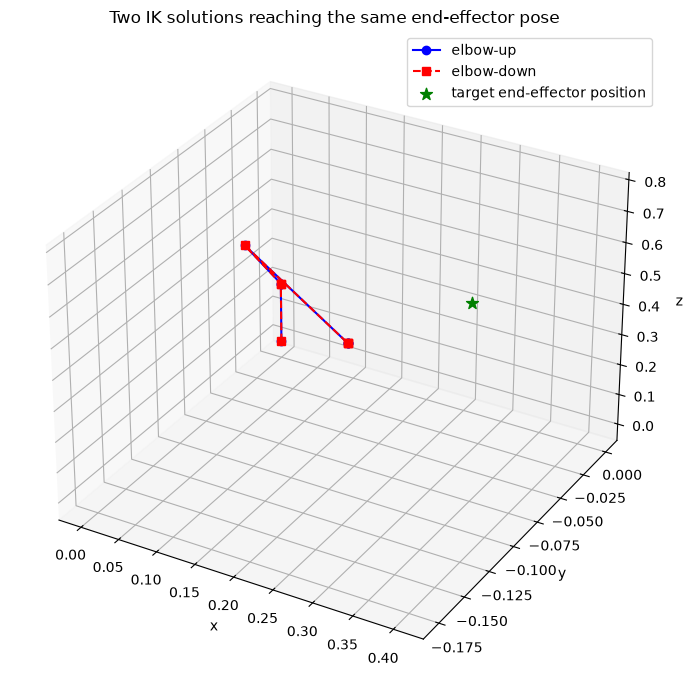

In [50]:
def frame_origins(theta):
    frames = compute_joint_frames(list(theta))
    return np.array([f[0:3, 3] for f in frames])


elbow_up = solutions_demo[7]     # shoulder-left/elbow-up/wrist-noflip (index 7 above)
elbow_down = solutions_demo[3]   # shoulder-left/elbow-down/wrist-noflip

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')
for sol, style, label in [(elbow_up, 'o-b', 'elbow-up'), (elbow_down, 's--r', 'elbow-down')]:
    pts = frame_origins(sol)
    ax.plot(pts[:, 0], pts[:, 1], pts[:, 2], style, label=label)
target_pos = target_demo[0:3, 3]
ax.scatter(*target_pos, c='green', s=80, marker='*', label='target end-effector position')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('z')
ax.set_title('Two IK solutions reaching the same end-effector pose')
ax.legend()
plt.tight_layout()
plt.show()


## 6. Singularities - what the clamps are actually guarding against

At the all-zero joint configuration, the elbow (`th3`) is fully extended - a
textbook singularity. Show what `cos(th3)`'s raw argument looks like there
(it can land a few ULPs past `1.0`), and why `np.clip` is what turns a `NaN`
into a well-defined (if degenerate) answer.

In [51]:
q_singular = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0])
target_singular = compute_fk(7, q_singular)

shoulder_offset = l6 + d2
R = target_singular[0:3, 0:3]
p = target_singular[0:3, 3]
p_wrist = p - R @ np.array([-l7, 0, le])
x_w, y_w, z_w = p_wrist
planar_reach = np.sqrt(max(0.0, x_w**2 + y_w**2 - shoulder_offset**2))
raw_cos_th3 = (planar_reach**2 + (z_w - l1)**2 - l3**2 - l5**2) / (2 * l3 * l5)

print("raw cos(th3) argument at the all-zero pose:", raw_cos_th3)
print("would sqrt(1 - cos^2) be NaN without clamping?",
      np.isnan(np.sqrt(1 - raw_cos_th3**2)) if abs(raw_cos_th3) > 1 else "no (in range here)")
print("clamped cos(th3):", np.clip(raw_cos_th3, -1.0, 1.0))
print()
print("This is exactly why analytical_ik_all_solutions clips cos_th3 (and cos_th5,")
print("and reach_sq) before ever calling sqrt/arccos - a numerics guard, not a")
print("derivation fix; the *geometric* singularity (elbow fully extended) is real")
print("and expected, only the NaN-from-floating-point-overshoot part is a bug to avoid.")


raw cos(th3) argument at the all-zero pose: 1.0000000000000007
would sqrt(1 - cos^2) be NaN without clamping? True
clamped cos(th3): 1.0

This is exactly why analytical_ik_all_solutions clips cos_th3 (and cos_th5,
and reach_sq) before ever calling sqrt/arccos - a numerics guard, not a
derivation fix; the *geometric* singularity (elbow fully extended) is real
and expected, only the NaN-from-floating-point-overshoot part is a bug to avoid.


/tmp/ipykernel_834085/2034628071.py:14: RuntimeWarning: invalid value encountered in sqrt
  np.isnan(np.sqrt(1 - raw_cos_th3**2)) if abs(raw_cos_th3) > 1 else "no (in range here)")


## 7. Bonus: trajectory planning (trapezoidal velocity profile)

Separate from FK/IK entirely - this is what `trajectory_planner`'s
`TrapezoidalTrajectoryGenerator` does: given a total distance and
`max_velocity`/`max_acceleration`, decide **when** to be at each point along an
already-planned path (never *where* - that's `path_planner`/`path_interpolator`'s
job).

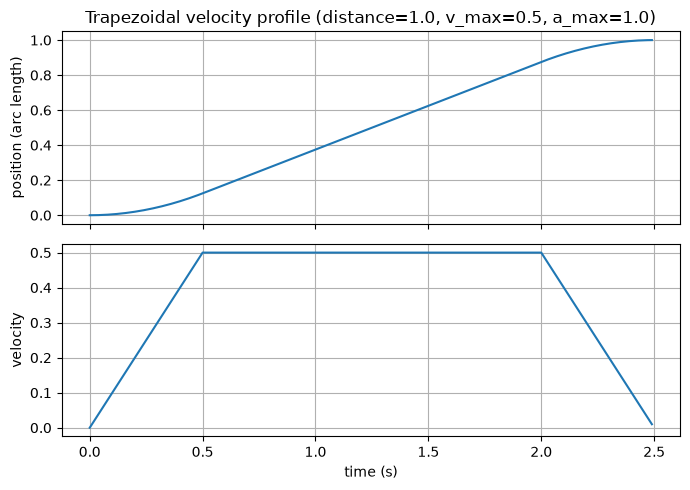

short move (0.05m): peak velocity reached = 0.220 (v_max=0.5 - never reached -> triangular profile, as expected)


In [52]:
def trapezoidal_profile(distance, v_max, a_max, dt=0.01):
    t_a = v_max / a_max
    d_a = 0.5 * a_max * t_a**2

    if 2 * d_a >= distance:
        # too short to ever reach v_max - triangular profile
        t_a = np.sqrt(distance / a_max)
        v_peak = a_max * t_a
        total_time = 2 * t_a
    else:
        v_peak = v_max
        cruise_dist = distance - 2 * d_a
        cruise_time = cruise_dist / v_max
        total_time = 2 * t_a + cruise_time

    ts = np.arange(0, total_time, dt)
    s, v = [], []
    for t in ts:
        if t <= t_a:
            s.append(0.5 * a_max * t**2)
            v.append(a_max * t)
        elif t <= total_time - t_a:
            s.append(d_a + v_peak * (t - t_a))
            v.append(v_peak)
        else:
            td = total_time - t
            s.append(distance - 0.5 * a_max * td**2)
            v.append(a_max * td)
    return ts, np.array(s), np.array(v)


ts, s, v = trapezoidal_profile(distance=1.0, v_max=0.5, a_max=1.0)
fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
axes[0].plot(ts, s); axes[0].set_ylabel('position (arc length)'); axes[0].grid(True)
axes[1].plot(ts, v); axes[1].set_ylabel('velocity'); axes[1].set_xlabel('time (s)'); axes[1].grid(True)
axes[0].set_title('Trapezoidal velocity profile (distance=1.0, v_max=0.5, a_max=1.0)')
plt.tight_layout()
plt.show()

ts_short, s_short, v_short = trapezoidal_profile(distance=0.05, v_max=0.5, a_max=1.0)
print(f"short move (0.05m): peak velocity reached = {v_short.max():.3f} "
      f"(v_max={0.5} - never reached -> triangular profile, as expected)")


## 8. Where this goes next

Every formula above is a 1:1 port target for:

- `kinematics/include/kinematics/strategy/analytical_six_axis_forward_kinematics.hpp/.cpp`
- `kinematics/include/kinematics/strategy/analytical_six_axis_inverse_kinematics.hpp/.cpp`
- `trajectory_planner/include/trajectory_planner/strategy/trapezoidal_trajectory_generator.hpp/.cpp`

If you change link lengths, add a new joint, or derive IK for a different robot
geometry: do it here first, re-run every cell (the assertions in Sections 2 and 4
will tell you immediately if something stopped matching), *then* port the change
to the C++ strategy - and add/update the matching regression test in
`integration_tests/test/test_kinematics.cpp` before considering it done, exactly
like `AnalyticalKinematics.IkRoundTripsToMachinePrecisionOnSphericalWrist` and
`CartesianVelocity.KdlAndAnalyticalJacobiansAgree` already do.